In [1]:
from astropy.table import Table,unique
import sys
sys.path.append("/home/tschiwy/ExTRA/")
import ExTRA as ex
import numpy as np
from astropy.time import Time
from scipy.optimize import minimize


ExTRA  imported correctly


# RV

In [2]:
folder="~/gaiaprep/gaia-dr4-prerelease-epoch-astrometry_2026-06-26/data/HD114762_RVs_trifon/"
#RV_FIES=Table.read(folder+"gaia-4b_FIES.dat",format="ascii")
#RV_HPF=Table.read(folder+"gaia-4b_HPF.dat",format="ascii")
#RV_NEID=Table.read(folder+"gaia-4b_NEID.dat",format="ascii")
#RV_HARPS=Table.read(folder+"gaia-4b_NEID.dat",format="ascii")

In [3]:
file=folder+"HD114762_Lick_Kane2011_74RVs.txt"
#file="~/RandomRVs/HD114762_Lick_Kane2011_74RVs.txt"
d=Table.read(file,format="ascii")
RVs=[ex.astropy_to_numpy(d[d.colnames[:3]])]
RV_instruments=["Lick"]

from pathlib import Path
RVs=[]
RV_instruments=[]
directory = Path(folder)

for file in directory.iterdir():
    RV_instruments.append(file.name.rsplit("_")[1])
    d=Table.read(file,format="ascii")["rjd","vrad","svrad"]
    for col in d.colnames:
        d=d[d[col] != '---']
    d["rjd"]=d["rjd"].astype(float)+2400000
    RVs.append(ex.astropy_to_numpy(d))


# Astrometry

In [4]:
hippath="/home/tschiwy/HIP/ResRec_JavaTool_2014/ResRec_JavaTool_2014/"
rawhip=ex.hip_data(hippath,"64426")

In [5]:
hip_sss=np.array(rawhip[1][5][:5]).astype(float)
hip_iad_processed=ex.hip_init(ex.astropy_to_numpy(rawhip[0]))[0]
hip_measurement=ex.abs_res(hip_iad_processed[-2],np.zeros(5),np.concatenate([[0,0],hip_sss[2:]]),hip_iad_processed)
hip_iad=np.copy(hip_iad_processed)
hip_iad[-2]=hip_measurement

In [6]:
ra0=198.07929227573089292491#deg # 0.0129 
dec0=17.51712379963620591639 #deg #0.0125
#plx=25.631658773243302  #0.0208
#muasc=-582.0292409120675 
#mudec=-0.70866711387231
#mu_err=[0.020,0.016]

dr4_lpc=[0.00136585289154092277,-0.00012322425210807282,25.6316587732433021074,-582.02924091206750745187,-0.7086671138723146246]
cpo=(ra0,dec0)
  

#Gaia Single Star Solution, stolen from git bh3
#the single star solution should always be given in DR4 , as with HIP
#g_asc=ra0
#g_dec=dec0
#g_par=plx
#g_mua=muasc
#g_mud=mudec
#dr3_sss=np.array([g_asc,g_dec,g_par,g_mua,g_mud])

In [7]:
data=Table.read("/home/tschiwy/gaiaprep/gaia-dr4-prerelease-epoch-astrometry_2026-06-26/data/dr4_reduction_id_3937211745905473024_with_sss.d",format="ascii")

In [8]:
d=data[data.colnames[2:-1]]
ast=ex.astropy_to_numpy(d)
gaia,t_gaia=ex.gaia_init(ast,standardepoch=2017.5)


In [9]:
#dr3_sss_rad=np.concatenate([np.radians(dr3_sss[:2]),dr3_sss[2:]])
#dr3_lpc=np.concatenate([[0,0],dr3_sss[2:]])

In [10]:
def L_hip_rigorous(planet_mas,sss_corr,iad_hip,sss_hip,cpo_gaia,sss_gaia,Sepoch=ex.J2017(),v_rad=0,s=0):    
    
    A3,A4,A5,A6,A7,A8,A9=hip_iad


    # the first two entries of sss_gaia are the SHIFTS to the comparison point !
    sss_lpc=sss_gaia+sss_corr

    
    #timestamps from data

    
    t_JD=ex.hip_JD(hip_iad,format="jd")

    
    xi_g,eta_g,plx_g,t_ltd=ex.propagate_lpc(sss_lpc,cpo_gaia,t_JD,v_rad=v_rad,Sepoch=Sepoch)
    x_sum,y_sum=ex.orbit_total(planet_mas,t_ltd)

    cpo_hip=hip_sss[:2]
    xi_h,eta_h=ex.gaia_lpc_to_hip_lpc(xi_g+x_sum, eta_g+y_sum ,cpo_gaia, cpo_hip)

    #print(xi_h,eta_h)
    
    res_final=A8-(A3*xi_h+A4*eta_h)-plx_g*A5

    


    
    #print(t_ltd-t_JD)
    #error
    A9=np.array(A9)

    L_hip=ex.loglikelihood(res_final,A9,s)
    
    #print(L_hip)

    return L_hip

In [11]:
def L_gaia_rigorous(planet_mas,sss_corr,gaia_iad,cpo_gaia,sss_gaia,Sepoch=ex.J2017(),v_rad=0,s=0):    

    #print(len(gaia_iad))
    
    A3,A4,A5,A6,A7,A8,A9=gaia_iad

    sss_lpc=sss_gaia+sss_corr

    
    #timestamps from data

    
    t_JD=ex.gaia_JD(gaia_iad,format="jd")


    xi_g,eta_g,plx_g,t_ltd=ex.propagate_lpc(sss_lpc,cpo_gaia,t_JD,v_rad=v_rad,Sepoch=Sepoch)
    
    x_sum,y_sum=ex.orbit_total(planet_mas,t_ltd)

    
    

    res_final=A8-(A3*(xi_g+x_sum)+A4*(eta_g+y_sum))-A5*plx_g
    
    
    #error
    A9=np.array(A9)

    L_gaia=ex.loglikelihood(res_final,A9,s)

    return L_gaia

In [12]:
import numpy as np
from scipy.optimize import brentq

def estimate_jitter(res, err):
    """Max-likelihood jitter s for a single instrument, given current residuals."""
    r2, e2 = res**2, err**2

    def g(s2):
        v = e2 + s2
        return np.sum((r2 - v) / v**2)

    if g(0.0) <= 0:          # errors already cover the scatter -> no jitter needed
        return 0.0

    s=np.sqrt(brentq(g, 0.0, r2.max()))
    if s>30:
        return 30
    else:
        return s 


In [13]:
def L_total(theta,gaia,hip,RVs,v_rad=0):
    n_offsets=int(-1*len(RVs))
    #n_jitters=int(-1*len(RVs))
    ast_theta=theta[:n_offsets]
    orb_par=np.array(ast_theta[5:])
    v0=theta[n_offsets:]
    #s=theta[n_jitters:]
    #print(v0)
    #print(s)
    corr=ast_theta[:5]
    


    iad_hip,sss_hip=hip
    iad_gaia,cpo_gaia,sss_gaia=gaia
    #print(iad_gaia)


    #conversion of a for astrometry
    planet_mas=np.copy(orb_par)
    planet_mas[-1]=orb_par[-1]*sss_gaia[2]
    #gaia
    l_gaia=L_gaia_rigorous(planet_mas,corr,iad_gaia,cpo_gaia,sss_gaia,v_rad=v_rad)
    #hip
    l_hip=L_hip_rigorous(planet_mas,corr,iad_hip,sss_hip,cpo_gaia,sss_gaia,v_rad=v_rad)


    



    #rvfit
    s=np.zeros(len(RVs))
    
    l_rvs=0
    for index,offset in enumerate(range(len(RVs))):
        RV_mod_timestamps=ex.RV_comb(v0[offset],orb_par,RVs[offset][0])
        s[offset]=estimate_jitter(RVs[offset][1]-RV_mod_timestamps,RVs[offset][2])
        print(s[offset])
        l_rvs+=ex.L_RVs_comb(*RVs[offset],s[offset],v0[offset],orb_par)
        
        
        


    l_all=l_rvs+l_gaia+l_hip
    print("R",l_rvs)
    print("g",l_gaia)
    print("H",l_hip)
    return l_all

In [14]:

HIP_all=hip_iad,hip_sss
GAIA_all=gaia,cpo,dr4_lpc

In [15]:
cpo
dr4_lpc

[0.0013658528915409228,
 -0.00012322425210807282,
 25.631658773243302,
 -582.0292409120675,
 -0.7086671138723146]

In [16]:
dr4_lpc[2:3]

[25.631658773243302]

In [17]:
P_g=84
e_g=0.33
om_g=np.radians(-160)
i_g=np.radians(0)
Om_g=np.radians(100)
T0_g=ex.J2017()
a_g=5
#guess
orb=np.array([P_g,e_g,om_g,i_g,Om_g,T0_g,a_g])
stand_corr=np.zeros(5)
x0=np.concatenate([stand_corr,orb])

#bounds
orbbnds=(P_g-30,P_g+30),(0,0.5),(-2*np.pi,2*np.pi),(0,1*np.pi),(-1*np.pi,1*np.pi),(T0_g-2*P_g,T0_g+2*P_g),(1e-3,10)
#orbbnds=(orb[0],orb[0]),(orb[1],orb[1]),(orb[2],orb[2]),(orb[3],orb[3]),(orb[4],orb[4]),(orb[5]-1,orb[5]+1),(orb[6],orb[6])

#orbbnds=(0,1000),(0,0.4),(0,2*np.pi),(np.radians(0),np.radians(180)),(-1*np.pi,1*np.pi),(T0_g-10000,T0_g+10000),(0,1)
standbnds=(-10,10),(-10,10),(-10,10),(-10,10),(-10,10)


bnds_v0=(-1e4,+1e4),
bnds_v=tuple()
for i in range(len(RVs)):
    bnds_v=bnds_v+bnds_v0
    x0=np.append(x0,200)


#bnds_s0=(10.7,10.9),
#bnds_s=tuple()
#for i in range(len(RVs)):
#    bnds_s=bnds_s+bnds_s0
#    x0=np.append(x0,10)
    



bnds=standbnds+orbbnds+bnds_v#+bnds_s

v_r=50
fit=minimize(L_total,x0,args=(GAIA_all,HIP_all,RVs,v_r),bounds=bnds,method="Nelder-mead",options={"maxiter":1e5,"fatol":1e-3,"xatol":1e-3})


30.0
R 6077.328661898605
g 172672456.96649075
H 49706.88998216087
30.0
R 6077.328661898605
g 172672514.78394428
H 49706.98145173207
30.0
R 6077.328661898605
g 172672218.55567765
H 49706.86177096628
30.0
R 6077.328661898605
g 172672529.31455743
H 49706.817140795916
30.0
R 6077.328661898605
g 172672628.95129395
H 49704.444125458576
30.0
R 6077.328661898605
g 172672406.9399361
H 49707.58261739802
30.0
R 6077.328661898605
g 133410456.81659716
H 51814.8760853817
30.0
R 6077.328661898605
g 173215670.0072863
H 50783.43050281315
30.0
R 6077.328661898605
g 166248993.01251394
H 48654.12101678135
30.0
R 6220.3177558233165
g 172672450.68737242
H 49706.888134281355
30.0
R 6077.328661898605
g 175790726.28373116
H 50206.118533529945
30.0
R 6077.328661898605
g 172672456.96649075
H 49706.88998216087
30.0
R 6077.328661898605
g 190557496.9098025
H 55109.064590818336
30.0
R 6163.265324759977
g 172672456.96649075
H 49706.88998216087
30.0
R 6144.956073841449
g 112785326.12824616
H 42100.92664880882
30.0
R 6

In [18]:
for i in range(5):
    x0=fit.x
    fit=minimize(L_total,x0,args=(GAIA_all,HIP_all,RVs),bounds=bnds,method="Nelder-mead",options={"maxiter":1e5,"fatol":1e-6,"xatol":1e-6})

30.0
R 5455.642665911699
g 27991.51325488092
H 434.7746574162834
30.0
R 5455.642665911699
g 27991.97665079851
H 434.717536000686
30.0
R 5455.642665911699
g 27991.853672500478
H 434.8125869580417
30.0
R 5455.642665911699
g 27991.590773401975
H 434.75482920018817
30.0
R 5455.642665911699
g 27993.541262046558
H 431.77749085566154
30.0
R 5455.642665911699
g 27991.72243623639
H 434.59737485527523
30.0
R 5455.642665911699
g 28787.63732812324
H 435.1372607030065
30.0
R 5455.642665911699
g 27991.530255025555
H 434.7665240964544
30.0
R 5455.642665911699
g 28010.788602702913
H 434.6711315387564
30.0
R 5455.518676324964
g 27991.51326702109
H 434.77465760634914
30.0
R 5455.642665911699
g 28001.37351791103
H 434.6977805204542
30.0
R 5455.642665911699
g 28094.747386548188
H 434.54263833309903
30.0
R 5455.642665911699
g 27952.22030188271
H 434.7477126618778
30.0
R 5455.81254234659
g 27991.51325488092
H 434.7746574162834
30.0
R 5455.685256797137
g 28736.637473015373
H 435.2008469179922
30.0
R 5455.601

for i in range(5):
    x0=fit.x
    fit=minimize(L_total,x0,args=(GAIA_all,HIP_all,RVs),bounds=bnds,method="Nelder-mead",options={"maxiter":1e3,"fatol":1e-8,"xatol":1e-8})

R 345.23358056512984
g 86.31773044318271
H 128.72364976606087

In [19]:
sss_fit=fit.x[:5]
planet_fit=fit.x[5:12]
idx_offsets=-len(RVs)
idx_jit=-len(RVs)

v0_fit=fit.x[idx_offsets:]
print(v0_fit)

[200.08813662]


In [20]:
print(sss_fit)
print(planet_fit)

[ 0.12649357  0.99450238 -0.33210496 -0.44470221  0.17759496]
[ 8.39131376e+01  3.29205951e-01 -2.76376755e+00  6.15411066e-02
  2.65323797e+00  2.45794481e+06  7.19027656e-02]


In [21]:
dr4_lpc_corr=dr4_lpc+sss_fit


alpha=planet_fit[-1]*(dr4_lpc_corr[2])
par_star=np.copy(planet_fit)
par_star[-1]=alpha

In [22]:
print("om,i,Om",np.degrees(planet_fit[2:5])%360)

om,i,Om [201.64778407   3.52604567 152.01933785]


In [23]:
import numpy as np
from scipy.optimize import brentq

def companion_mass(a1, P, M1):
    """
    a1: barycentric semi-major axis [AU]
    P: orbital period [yr]
    M1: primary mass [Msun]
    """

    f = lambda M2: M2**3 / (M1 + M2)**2 - a1**3 / P**2

    return brentq(f, 1e-12, 100*M1)

    companion_mass(planet_fit[-1],planet_fit[0],1)

In [24]:
gaia_binned=ex.bin_by_time(gaia)
#hip_binned=ex.bin_by_time(hip_iad)

In [25]:
#1 orbit model
t_1p=np.linspace(0,planet_fit[0],2000)
orbit_1p=ex.orbit(par_star,t_1p)


In [26]:
def gaia_residuals(planet_fit,sss_fit,gaia,cpo,dr4_lpc,v_r=0):
    A3,A4,A5,A6,A7,A8,A9=gaia

    #dr3_lpc=np.concatenate([[sss_fit[0],sss_fit[1]],dr3_sss[2:]+sss_fit[2:]])
    #cpo=(dr3_sss[0],dr3_sss[1])
    t_gaia=ex.gaia_JD(gaia,Sepoch=ex.J2017())
    dr4_lpc_corr=dr4_lpc+sss_fit
    prop=ex.propagate_lpc(dr4_lpc_corr,cpo,t_gaia,v_rad=v_r,Sepoch=ex.J2017())
    t_ltd=prop[-1]
    al_res=A8-prop[0]*A3-prop[1]*A4-prop[2]*A5




    alpha=planet_fit[-1]*(dr4_lpc_corr[2])
    #print(alpha)
    par_star=np.copy(planet_fit)
    par_star[-1]=alpha

    x_sum,y_sum=ex.orbit_total(par_star,t_ltd)
    res_final=al_res-(A3*x_sum+A4*y_sum)
    #fit_residuals=ex.abs_res(gaia[-2],fit.x[0:5],np.zeros(5),gaia[:5])

    return t_ltd,res_final,ex.res_to_orbit_gaia(res_final,gaia, par_star)

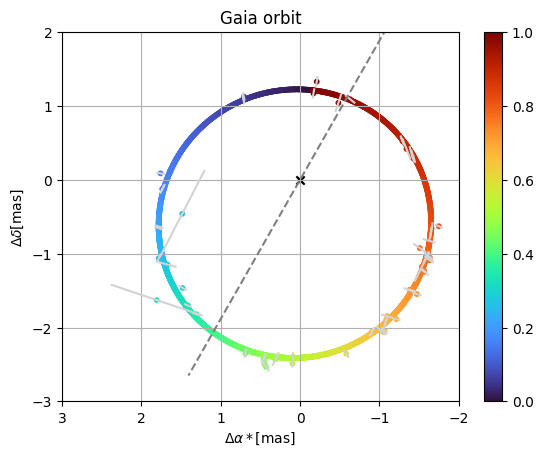

In [27]:
import matplotlib.pyplot as plt
#res2d
t_gaia_bin,gaia_res_final_bin,gaia_res_2d_bin=gaia_residuals(planet_fit,sss_fit,gaia_binned,cpo,dr4_lpc,v_r=v_r)


t_gaia,gaia_res_final,gaia_res_2d=gaia_residuals(planet_fit,sss_fit,gaia,cpo,dr4_lpc,v_r=v_r)
#model
t_model=np.linspace(t_gaia[0],t_gaia[-1],2000)


orbit_model=ex.orbit(par_star,t_model)







plt.title("Gaia orbit")
plt.xlabel(r"$\Delta\alpha*$[mas]")
plt.ylabel(r"$\Delta\delta$[mas]")

plt.scatter(0,0,c="k",marker="x")
cmap = plt.get_cmap("turbo")
color = cmap((t_gaia_bin-planet_fit[-2])% planet_fit[0] /planet_fit[0])
color_mod=cmap((t_model-planet_fit[-2])%planet_fit[0] /planet_fit[0])


#plt.plot(*ex.orbit(planet_fit,t_mod_ast),c="k")
plt.scatter(*orbit_model,c=color_mod,s=10)
ex.plot_hip_err(*gaia_res_2d_bin,co=color,s=10)
plt.scatter(0,0,c="k",s=20,marker="x")

import matplotlib
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=plt.gcf().axes)

Omega = planet_fit[4]  # if in degrees

r = 3

plt.plot(
    [-r*np.sin(Omega), r*np.sin(Omega)],
    [-r*np.cos(Omega), r*np.cos(Omega)],
    '--', color='grey', label='Line of nodes'
)


plt.xlim([-2,3])
plt.ylim([-3,2])
plt.gca().invert_xaxis()
plt.grid()
plt.savefig("pics/gaia_2d")

plt.title("Gaia residuals")
plt.xlabel(r"$\Delta\alpha*$[mas]")
plt.ylabel(r"$\Delta\delta$[mas]")

plt.scatter(0,0,c="k",marker="x")
cmap = plt.get_cmap("turbo")
color = cmap((t_gaia-planet_fit[-2])% planet_fit[0] /planet_fit[0])
color_mod=cmap((t_model-planet_fit[-2])%planet_fit[0] /planet_fit[0])


#plt.plot(*ex.orbit(planet_fit,t_mod_ast),c="k")

plt.scatter(*orbit_model,c=color_mod,s=10)
ex.plot_hip(*gaia_res_2d,size=0.1,co=color,s=10)

plt.scatter(0,0,c="k",s=20,marker="x")

import matplotlib
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=plt.gcf().axes)


plt.gca().invert_xaxis()
plt.axis("equal")
plt.grid()

#plt.errorbar(t_gaia,gaia_res_2d[0],yerr=abs(gaia_res_2d[1]),c="k",linestyle="")
plt.scatter(t_gaia,gaia_res_2d[0],c="lightgrey",linestyle="")


plt.errorbar(t_gaia_bin,gaia_res_2d_bin[0],yerr=abs(gaia_res_2d_bin[1]),c="k",linestyle="")
plt.scatter(t_gaia_bin,gaia_res_2d_bin[0],c="r",linestyle="")

plt.title("orbital fit HD 114762; GaiaDR4 residuals")
plt.ylabel("RA res [mas]")
plt.xlabel("t JD")
plt.plot(t_model,orbit_model[0],c="b",linestyle="--")
plt.grid()
plt.savefig("pics/gaia_asc")
plt.show()

#plt.errorbar(t_gaia,gaia_res_2d[0],yerr=abs(gaia_res_2d[1]),c="k",linestyle="")
plt.scatter(t_gaia,gaia_res_2d[2],c="lightgrey",linestyle="")


plt.errorbar(t_gaia_bin,gaia_res_2d_bin[2],yerr=abs(gaia_res_2d_bin[3]),c="k",linestyle="")
plt.scatter(t_gaia_bin,gaia_res_2d_bin[2],c="r",linestyle="")

plt.title("orbital fit HD 114762; GaiaDR4 residuals")
plt.ylabel("RA res [mas]")
plt.xlabel("t JD")
plt.plot(t_model,orbit_model[1],c="b",linestyle="--")
plt.grid()
plt.savefig("pics/gaia_dec")
plt.show()


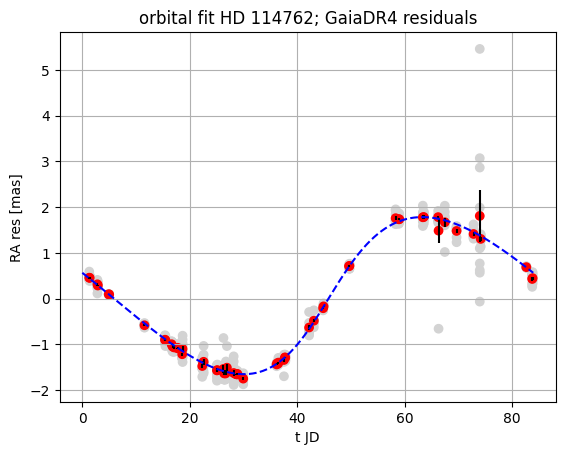

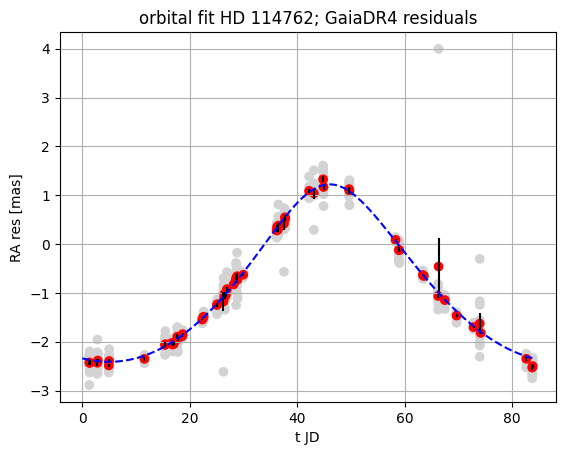

In [28]:
#plt.errorbar(t_gaia,gaia_res_2d[0],yerr=abs(gaia_res_2d[1]),c="k",linestyle="")
 

gaia_phase_bin=(t_gaia_bin)%planet_fit[0]  #/planet_fit[0]
gaia_phase=(t_gaia)%planet_fit[0] #/planet_fit[0]

plt.scatter(gaia_phase,gaia_res_2d[0],c="lightgrey",linestyle="")
plt.errorbar(gaia_phase_bin,gaia_res_2d_bin[0],yerr=abs(gaia_res_2d_bin[1]),c="k",linestyle="")
plt.scatter(gaia_phase_bin,gaia_res_2d_bin[0],c="r",linestyle="")

plt.title("orbital fit HD 114762; GaiaDR4 residuals")
plt.ylabel("RA res [mas]")
plt.xlabel("t JD")
plt.plot(t_1p,orbit_1p[0],c="b",linestyle="--")
plt.grid()
plt.savefig("pics/gaia_asc")
plt.show()

#plt.errorbar(t_gaia,gaia_res_2d[0],yerr=abs(gaia_res_2d[1]),c="k",linestyle="")
plt.scatter(gaia_phase,gaia_res_2d[2],c="lightgrey",linestyle="")


plt.errorbar(gaia_phase_bin,gaia_res_2d_bin[2],yerr=abs(gaia_res_2d_bin[3]),c="k",linestyle="")
plt.scatter(gaia_phase_bin,gaia_res_2d_bin[2],c="r",linestyle="")

plt.title("orbital fit HD 114762; GaiaDR4 residuals")
plt.ylabel("RA res [mas]")
plt.xlabel("t JD")
plt.plot(t_1p,orbit_1p[1],c="b",linestyle="--")
plt.grid()
plt.savefig("pics/gaia_dec")
plt.show()


In [29]:
def hip_residuals(planet_fit,sss_fit,hip_iad,hip_sss,cpo,dr4_lpc,v_r=0):
    A3_h,A4_h,A5_h,A6_h,A7_h,A8_h,A9_h=hip_iad


    # the first two entries of sss_gaia are the SHIFTS to the comparison point !
    sss_lpc=dr4_lpc+sss_fit


    #timestamps from data


    t_hip_jd=ex.hip_JD(hip_iad,format="jd")
    xi_g,eta_g,plx_g,t_ltd=ex.propagate_lpc(sss_lpc,cpo,t_hip_jd,v_rad=v_r)

    alpha=planet_fit[-1]*(dr4_lpc[2])
    par_star=np.copy(planet_fit)
    par_star[-1]=alpha

    x_sum,y_sum=ex.orbit_total(par_star,t_ltd)

    cpo_hip=hip_sss[:2]
    xi_h,eta_h=ex.gaia_lpc_to_hip_lpc(xi_g+x_sum, eta_g+y_sum ,cpo, hip_sss[:2])


    #print(xi_h,eta_h)

    res_final_h=A8_h-(A3_h*xi_h+A4_h*eta_h)-plx_g*A5_h

    return t_ltd,res_final_h,ex.res_to_orbit(res_final_h,hip_iad, par_star)

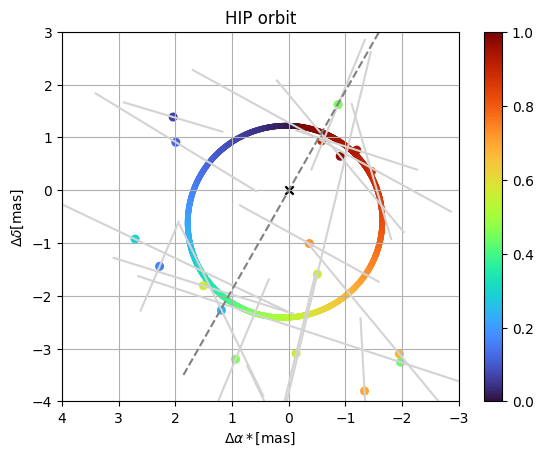

In [30]:
hip_iad_bin=ex.bin_by_time(hip_iad)


#res2d

t_JD_hip_bin,hip_res_final_bin,hip_res_2d_bin=hip_residuals(planet_fit,sss_fit,hip_iad_bin,hip_sss,cpo,dr4_lpc,v_r=v_r)

t_JD_hip,hip_res_final,hip_res_2d=hip_residuals(planet_fit,sss_fit,hip_iad,hip_sss,cpo,dr4_lpc,v_r=v_r)

t_model_hip=np.linspace(t_JD_hip[0],t_JD_hip[-1],2000)
orbit_model_h=ex.orbit(par_star,t_model_hip)






####
plt.title("HIP residuals")
plt.ylabel("DEC[mas]")
plt.xlabel("RA[mas]")

plt.scatter(0,0,c="k",marker="x")


hip_phase_bin=(t_JD_hip_bin-planet_fit[-2])%planet_fit[0] /planet_fit[0]
hip_phase=(t_JD_hip-planet_fit[-2])%planet_fit[0] /planet_fit[0]

cmap = plt.get_cmap("turbo")
color = cmap((t_JD_hip_bin-planet_fit[-2])%planet_fit[0] /planet_fit[0])
color_mod=cmap((t_model_hip-planet_fit[-2])%planet_fit[0] /planet_fit[0])

sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=plt.gcf().axes)



plt.scatter(*orbit_model_h,c=color_mod,s=10)
ex.plot_hip_err(*hip_res_2d_bin,co=color,s=30)
plt.scatter(0,0,c="k",s=20,marker="x")
plt.title("HIP orbit")
plt.xlabel(r"$\Delta\alpha*$[mas]")
plt.ylabel(r"$\Delta\delta$[mas]")
r = 4

plt.plot(
    [-r*np.sin(Omega), r*np.sin(Omega)],
    [-r*np.cos(Omega), r*np.cos(Omega)],
    '--', color='grey', label='Line of nodes'
)

plt.xlim([-3,4])
plt.ylim([-4,3])
plt.grid()
plt.gca().invert_xaxis()
plt.savefig("pics/hip_2d")

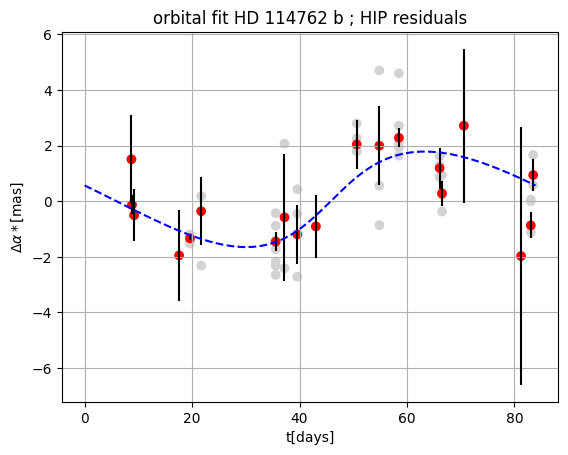

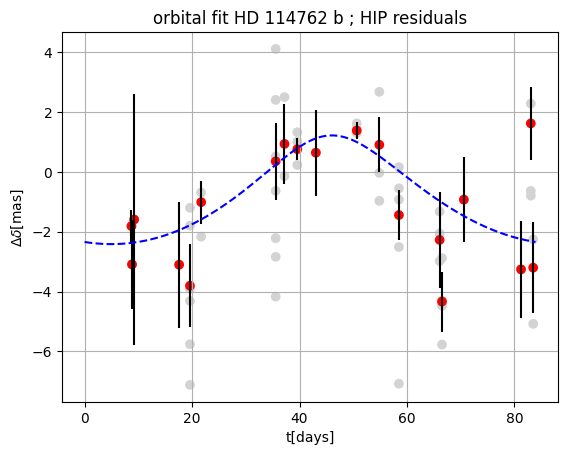

In [31]:

hip_phase_bin=(t_JD_hip_bin)%planet_fit[0]  #/planet_fit[0]
hip_phase=(t_JD_hip)%planet_fit[0] #/planet_fit[0]



plt.scatter(hip_phase,hip_res_2d[0],c="lightgrey",linestyle="")
plt.errorbar(hip_phase_bin,hip_res_2d_bin[0],yerr=abs(hip_res_2d_bin[1]),c="k",linestyle="")
plt.scatter(hip_phase_bin,hip_res_2d_bin[0],c="r",linestyle="")

plt.title("orbital fit HD 114762 b ; HIP residuals")


plt.ylabel(r"$\Delta\alpha*$[mas]")
plt.xlabel("t[days]")
plt.plot(t_1p,orbit_1p[0],c="b",linestyle="--")
plt.grid()
plt.savefig("pics/hip_asc")
plt.show()

#plt.errorbar(t_gaia,gaia_res_2d[0],yerr=abs(gaia_res_2d[1]),c="k",linestyle="")


plt.scatter(hip_phase,hip_res_2d[2],c="lightgrey",linestyle="")
plt.errorbar(hip_phase_bin,hip_res_2d_bin[2],yerr=abs(hip_res_2d_bin[3]),c="k",linestyle="")
plt.scatter(hip_phase_bin,hip_res_2d_bin[2],c="r",linestyle="")

plt.title("orbital fit HD 114762 b ; HIP residuals")
plt.ylabel(r"$\Delta\delta$[mas]")
plt.xlabel("t[days]")
plt.plot(t_1p,orbit_1p[1],c="b",linestyle="--")
plt.grid()
plt.savefig("pics/hip_dec")
plt.show()



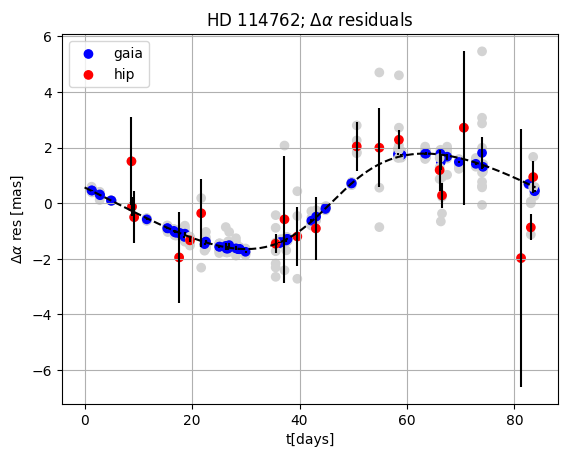

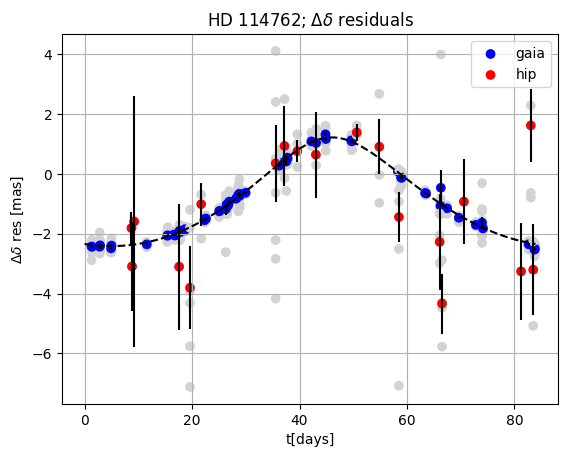

In [32]:

hip_phase_bin=(t_JD_hip_bin)%planet_fit[0] #/planet_fit[0]
hip_phase=(t_JD_hip)%planet_fit[0] #/planet_fit[0]

gaia_phase_bin=(t_gaia_bin)%planet_fit[0] #/planet_fit[0]
gaia_phase=(t_gaia)%planet_fit[0] #/planet_fit[0]





plt.scatter(gaia_phase,gaia_res_2d[0],c="lightgrey",linestyle="")
plt.errorbar(gaia_phase_bin,gaia_res_2d_bin[0],yerr=abs(gaia_res_2d_bin[1]),c="k",linestyle="")
plt.scatter(gaia_phase_bin,gaia_res_2d_bin[0],c="b",linestyle="",label="gaia")

plt.scatter(hip_phase,hip_res_2d[0],c="lightgrey",linestyle="")
plt.errorbar(hip_phase_bin,hip_res_2d_bin[0],yerr=abs(hip_res_2d_bin[1]),c="k",linestyle="")
plt.scatter(hip_phase_bin,hip_res_2d_bin[0],c="r",linestyle="",label="hip")
plt.grid()







plt.title(r"HD 114762; $\Delta\alpha$ residuals")
plt.ylabel(r"$\Delta\alpha$ res [mas]")
plt.xlabel("t[days]")
plt.plot(t_1p,orbit_1p[0],c="k",linestyle="--")
plt.legend()
plt.savefig("pics/h+g_asc")
plt.show()


#plt.errorbar(t_gaia,gaia_res_2d[0],yerr=abs(gaia_res_2d[1]),c="k",linestyle="")




#plt.errorbar(t_gaia,gaia_res_2d[0],yerr=abs(gaia_res_2d[1]),c="k",linestyle="")
plt.scatter(gaia_phase,gaia_res_2d[2],c="lightgrey",linestyle="")


plt.errorbar(gaia_phase_bin,gaia_res_2d_bin[2],yerr=abs(gaia_res_2d_bin[3]),c="k",linestyle="")
plt.scatter(gaia_phase_bin,gaia_res_2d_bin[2],c="b",linestyle="",label="gaia")



plt.scatter(hip_phase,hip_res_2d[2],c="lightgrey",linestyle="")
plt.errorbar(hip_phase_bin,hip_res_2d_bin[2],yerr=abs(hip_res_2d_bin[3]),c="k",linestyle="")
plt.scatter(hip_phase_bin,hip_res_2d_bin[2],c="r",linestyle="",label="hip")

plt.title(r"HD 114762; $\Delta\delta$ residuals")
plt.ylabel(r"$\Delta\delta$ res [mas]")
plt.xlabel("t[days]")
plt.plot(t_1p,orbit_1p[1],c="k",linestyle="--")
plt.legend()
plt.grid()
plt.savefig("pics/h+g_dec")
plt.show()

#plt.errorbar(t_gaia,gaia_res_2d[0],yerr=abs(gaia_res_2d[1]),c="k",linestyle="")








In [33]:


t_JD_hip_bin0,hip_res_final_bin0,hip_res_2d_bin0=hip_residuals(planet_fit,sss_fit,hip_iad_bin,hip_sss,cpo,dr4_lpc,v_r=0)

t_JD_hip0,hip_res_final0,hip_res_2d0=hip_residuals(planet_fit,sss_fit,hip_iad,hip_sss,cpo,dr4_lpc,v_r=0)

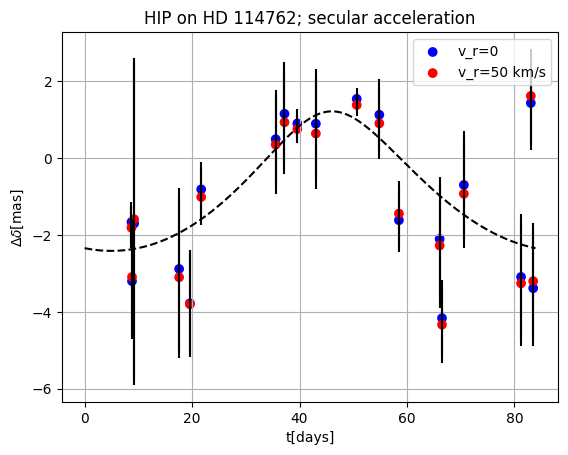

In [34]:

plt.title("HIP on HD 114762; secular acceleration")
plt.ylabel(r"$\Delta\delta$[mas]")
plt.xlabel("t[days]")


plt.errorbar(hip_phase_bin,hip_res_2d_bin0[2],yerr=abs(hip_res_2d_bin[3]),c="k",linestyle="")
plt.scatter(hip_phase_bin,hip_res_2d_bin0[2],c="b",linestyle="",label="v_r=0")
plt.errorbar(hip_phase_bin,hip_res_2d_bin[2],yerr=abs(hip_res_2d_bin[3]),c="k",linestyle="")
plt.scatter(hip_phase_bin,hip_res_2d_bin[2],c="r",linestyle="",label="v_r=50 km/s")
plt.plot(t_1p,orbit_1p[1],c="k",linestyle="--")
plt.legend()
plt.grid()
plt.savefig("pics/secular_dec")
plt.show()

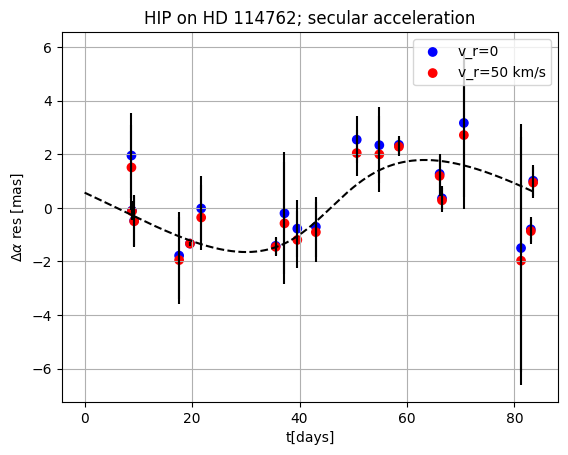

In [35]:
plt.title("HIP on HD 114762; secular acceleration")
plt.ylabel(r"$\Delta\alpha$ res [mas]")
plt.xlabel("t[days]")
plt.errorbar(hip_phase_bin,hip_res_2d_bin0[0],yerr=abs(hip_res_2d_bin[1]),c="k",linestyle="")
plt.scatter(hip_phase_bin,hip_res_2d_bin0[0],c="b",linestyle="",label="v_r=0")
plt.errorbar(hip_phase_bin,hip_res_2d_bin[0],yerr=abs(hip_res_2d_bin[1]),c="k",linestyle="")
plt.scatter(hip_phase_bin,hip_res_2d_bin[0],c="r",linestyle="",label="v_r=50 km/s")
plt.plot(t_1p,orbit_1p[0],c="k",linestyle="--")
plt.legend()
plt.grid()
plt.savefig("pics/secular_asc")
plt.show()

In [36]:
orbit_model_hip=ex.orbit(par_star,t_JD_hip_bin)
absorb=orbit_model_hip[0]*hip_iad_bin[0]+orbit_model_hip[1]*hip_iad_bin[1]


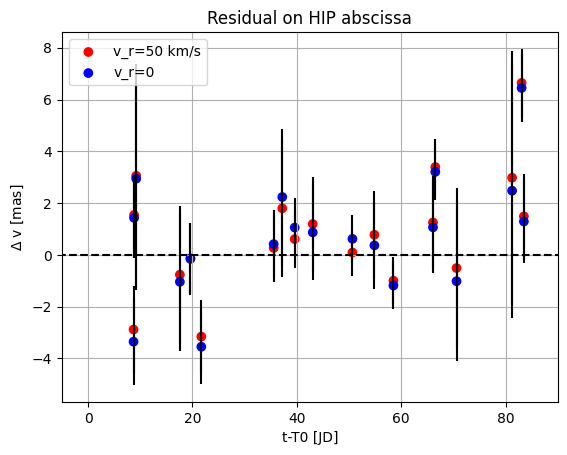

In [37]:
plt.errorbar(hip_phase_bin,hip_res_final_bin-absorb,yerr=abs(hip_iad_bin[-1]),c="k",linestyle="")
plt.scatter(hip_phase_bin,hip_res_final_bin-absorb,c="r",linestyle="",label="v_r=50 km/s")
plt.scatter(hip_phase_bin,hip_res_final_bin0-absorb,c="b",linestyle="",label="v_r=0")
plt.errorbar(hip_phase_bin,hip_res_final_bin0-absorb,yerr=abs(hip_iad_bin[-1]),c="k",linestyle="")

plt.hlines(0,-10,100,colors="k",linestyles="--")
plt.xlim([-5,90])

plt.legend()
plt.title("Residual on HIP abscissa")
plt.ylabel(r"$\Delta$ v [mas]")
plt.xlabel(r"t-T0 [JD]")
plt.grid()
plt.savefig("pics/absres")
plt.show()

In [38]:
redchi_hip=ex.chi_squared(hip_res_final,hip_iad[-1],0)/(len(hip_res_final-12))
print(redchi_hip)
redchi_gaia=ex.chi_squared(gaia_res_final,gaia[-1],0)/(len(gaia_res_final)-12)
print(redchi_gaia)

1.2086202453357666
9.849937494846673


# Chi

In [55]:
dr4_lpc[2]*planet_fit[-1]

np.float64(1.842987152040486)

In [39]:
ex.chi_squared(hip_res_final0,hip_iad[-1],0)/(len(hip_res_final0-12))

np.float64(1.258535578663454)

In [40]:
RV_t_all=[]
for i in range(len(RVs)):
    RV_t_all.extend(RVs[i][0])

t_mod=np.linspace(min(RV_t_all),max(RV_t_all),1000)

0


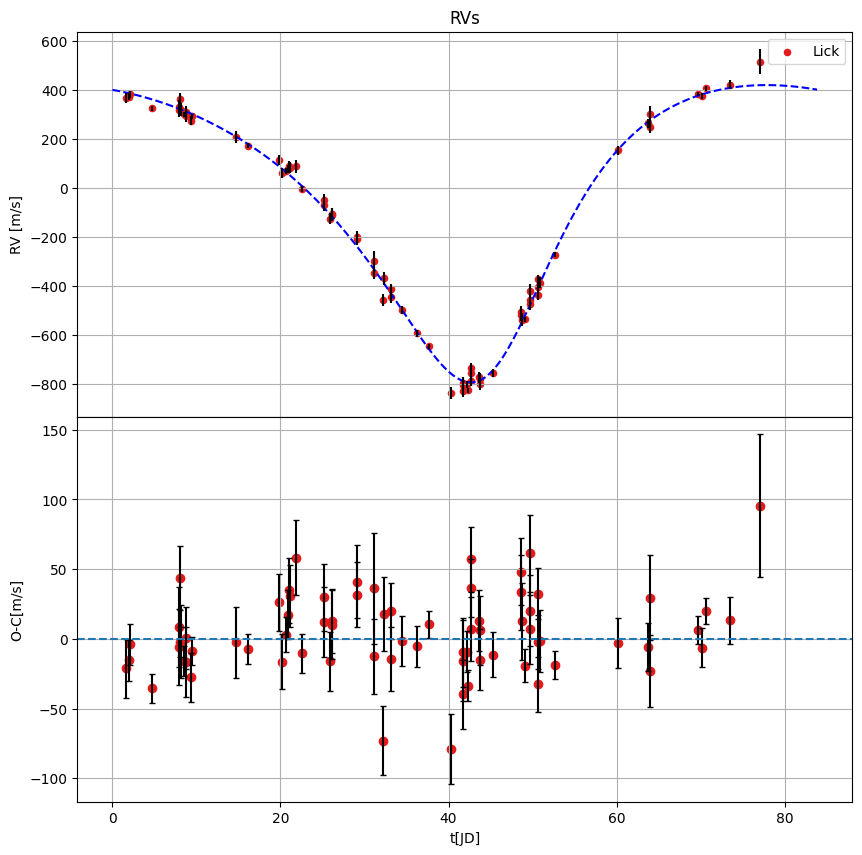

In [41]:
RV_t_all=[]
for i in range(len(RVs)):
    RV_t_all.extend(RVs[i][0])


#v0_fit=trifon_v0






##
fig,axs=plt.subplots(2,1,sharex=True)
fig.subplots_adjust(hspace=0)
fig.set_size_inches(10, 10)
colors = plt.cm.Set1(range(len(RVs)))



t_mod=np.sort(np.linspace(min(RV_t_all),max(RV_t_all),1000)%(planet_fit[0]))
RV_mod=ex.RV_comb(0,planet_fit,t_mod)
axs[0].plot(t_mod,RV_mod,linestyle="--",c="b")

axs[0].set_title("RVs")

for i in range(len(RVs)):

    

    tp=RVs[i][0]%(planet_fit[0])
    



    err=RVs[i][2]

    #print(t)
    print(i)
    rv_res=RVs[i][1]-v0_fit[i]
    axs[0].set_ylabel("RV [m/s]")
    axs[0].errorbar(tp,rv_res,err,linestyle="",c="k")
    axs[0].scatter(tp,rv_res,s=20,color=colors[i],label=RV_instruments[i])
    #axs[0].set_ylim([RVs[0][1].min(168.53334724228688)-100,RVs[0][1].max()+5])
    #axs[0].set_ylim([0,150])

    RV_mod_timestamps=ex.RV_comb(fit.x[-len(RVs)+i],planet_fit,RVs[i][0])
    RV_res=RVs[i][1]-RV_mod_timestamps
    axs[1].scatter(tp,RV_res,color=colors[i])
    axs[1].errorbar(tp,RV_res,abs(err),c="k",linestyle="",capsize=2)
    axs[1].axhline(0,linestyle="--")
    axs[1].set_ylabel("O-C[m/s]")
    axs[1].set_xlabel("t[JD]")
    #axs[1].set_ylim([-15,15])
    redchi_RV=ex.chi_squared(RV_res,err,13.411060572039494)/(len(err)-9)
    


    #plt.tight_layout()
    
axs[0].legend()
axs[0].grid()   
axs[1].grid() 
plt.savefig("pics/RVs")
plt.show()



In [42]:
import json
import numpy as np

da, dd, dplx, dmua, dmud = sss_fit
P, e, om, i, Om, T0, a   = planet_fit

params = {
    "dr4_comparison_point":    np.asarray(cpo, dtype=float).tolist(),      # arrays -> lists for JSON
    "dr4_agis": np.asarray(dr4_lpc, dtype=float).tolist(),
    "systemic RV": float(v_r),
    "5par_fit": np.asarray(sss_fit, dtype=float).tolist(),
    "P[d]": float(P), "e": float(e), "om": float(om), "i": float(i),
    "Om": float(Om), "T0[JD]": float(T0), "a(primary in AU)": float(a),
    "redchi_gaia": float(redchi_gaia),
    "redchi_hip":float(redchi_hip),
    "redchi_RV":float(redchi_RV),
    "rv_jitter":float(13.408)
}

with open("params.json", "w") as f:
    json.dump(params, f, indent=2)